<div class="alert alert-info" style="color: black;">
    
### AI USE DISCLAIMER & ACADEMIC INTEGRITY COMPLIANCE
In compliance with the [**National University Student Guidelines for Generative AI**](https://resources.nu.edu/ai/ai-guidelines), this project discloses the following tool usage:

* **Conceptual Framing & Brainstorming (AI-Informed):** **Google Gemini** was utilized as a supplemental learning resource to clarify core mathematical and analytical concepts across the assignment questions. 
* **Technical Execution & Boilerplate Generation (AI-Assisted):** **Google Gemini** was used to generate initial code structures and programming boilerplates. These templates were subsequently modified, debugged, and tailored to meet the specific requirements of each question.
* **Human Oversight, Validation Loops & Refinement (Author-Owned):** The author maintained complete conceptual control, process oversight, and ownership of the entire homework scope. All AI-assisted templates, code logic, and conceptual outputs were systematically reviewed and validated by the author to ensure academic accuracy and integrity.
* **Disclosure Statement (AI-Generated):** **Google Gemini** was utilized to structure and audit this text format to fulfill all institutional reporting standards.
</div>

**General Quadratic Penalty Function:** \
$Q(x, \rho) = f(x) + \frac{\rho}{2} \max(0, -g(x))^2$

**Objective Function:** \
$f(x) = 100(x - b)^2 + \pi$

**Constraint Function:** \
$g(x) = x - a \geq 0 \quad (a > b)$ \
$g(x) = a - x \leq 0$

**Quadratic Penalty Function (Applied):**
1. $Q(x, \rho) = 100(x - b)^2 + \pi + \frac{\rho}{2}(a - x)^2$
1. $\frac{d}{dx} Q(x; \rho) = 200(x - b) - \rho(a - x) = 0$
1. $200x - 200b - \rho a + \rho x = 0$
1. $(200 + \rho)x = 200b + \rho a$
1. $x = \frac{200b + \rho a}{200 + \rho}$
1. $x = \lim_{\rho \to \infty} \frac{200b + \rho a}{200 + \rho} = \lim_{\rho \to \infty} \frac{\frac{200b}{\rho} + a}{\frac{200}{\rho} + 1} = a$

**Optimal Point:** $x = a$ \
**Optimal Value:** $f(a) = 100(a - b)^2 + \pi$

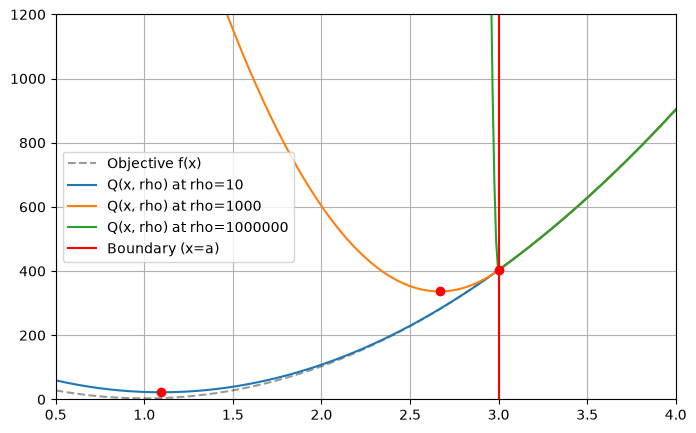

In [1]:
# ANA670 - Week 2 HW - Q1
import numpy as np
import matplotlib.pyplot as plt

b, a, pi = 1.0, 3.0, np.pi
x = np.linspace(0.5, 4.5, 400)
f = 100 * (x - b)**2 + pi

plt.figure(figsize=(8, 5))
plt.plot(x, f, 'k--', label='Objective f(x)', alpha=0.4)

for rho in [10, 1000, 1000000]:
    penalty = 0.5 * rho * np.maximum(0, a - x)**2
    Q = f + penalty
    
    x_rho = (200 * b + rho * a) / (200 + rho)
    y_rho = 100 * (x_rho - b)**2 + pi + 0.5 * rho * np.maximum(0, a - x_rho)**2
    
    plt.plot(x, Q, label=f'Q(x, rho) at rho={rho}')
    plt.plot(x_rho, y_rho, 'ro')

plt.axvline(x=a, color='r', label='Boundary (x=a)')
plt.xlim(0.5, 4.0); plt.ylim(0, 1200); plt.legend(); plt.grid(True)
plt.show()

In [2]:
# ANA670 - Week 2 HW - Q2
def cg(system, target):
    guess = np.zeros_like(target, dtype=float)
    error = target - system @ guess
    direction = error.copy()
    for _ in range(len(target)):
        if np.linalg.norm(error) < 1e-6:
            break
        step = (error @ error) / (direction @ system @ direction)
        guess += step * direction
        nxt_error = error - step * system @ direction
        factor = (nxt_error @ nxt_error) / (error @ error)
        direction = nxt_error + factor * direction
        error = nxt_error
    return guess

# Top row = Labor Hours (2 per Standard, 1 per Premium)
# Bottom row = Material Costs ($1 per Standard, $4 per Premium)
# Budget Targets (11,000 labor hours, $16,000 materials budget)
accounting_system = np.array([[2, 1], [1, 4]], dtype=float)
accounting_target = np.array([11000, 16000], dtype=float)
production_plan = cg(accounting_system, accounting_target)
used_resources = accounting_system @ production_plan

print("Recommended Production Quantities:", production_plan)
print("Budget Verification (System @ Plan): ", accounting_system @ production_plan)
print(f"\nStandard to Produce: {production_plan[0]:,.0f} units")
print(f"Premium to Produce:  {production_plan[1]:,.0f} units")
print(f"\nTotal Labor Hours Used:      {used_resources[0]:,.0f} / {accounting_target[0]:,.0f} hours")
print(f"Total Material Cost Used:    ${used_resources[1]:,.0f} / ${accounting_target[1]:,.0f}")

Recommended Production Quantities: [4000. 3000.]
Budget Verification (System @ Plan):  [11000. 16000.]

Standard to Produce: 4,000 units
Premium to Produce:  3,000 units

Total Labor Hours Used:      11,000 / 11,000 hours
Total Material Cost Used:    $16,000 / $16,000


Recommended Production Quantities: [4000. 3000.]
Budget Verification (System @ Plan):  [11000. 16000.]

Standard to Produce: 4,000 units
Premium to Produce:  3,000 units

Total Labor Hours Used:      11,000 / 11,000 hours
Total Material Cost Used:    $16,000 / $16,000


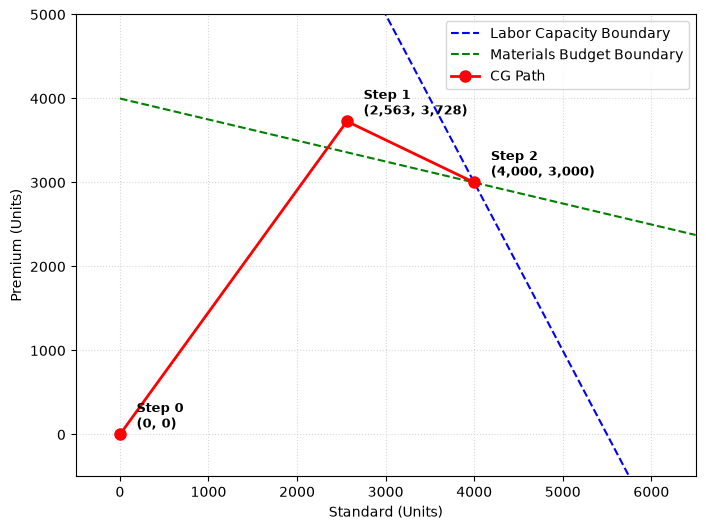

In [3]:
def cg(system, target):
    guess = np.zeros_like(target, dtype=float)
    error = target - system @ guess
    direction = error.copy()
    history = [guess.copy()]
    for _ in range(len(target)):
        if np.linalg.norm(error) < 1e-6:
            break
        step = (error @ error) / (direction @ system @ direction)
        guess += step * direction
        history.append(guess.copy())
        nxt_error = error - step * system @ direction
        factor = (nxt_error @ nxt_error) / (error @ error)
        direction = nxt_error + factor * direction
        error = nxt_error
    return guess, np.array(history)

# Top row = Labor Hours (2 per Standard, 1 per Premium)
# Bottom row = Material Costs ($1 per Standard, $4 per Premium)
# Budget Targets (11,000 labor hours, $16,000 materials budget)
accounting_system = np.array([[2, 1], [1, 4]], dtype=float)
accounting_target = np.array([11000, 16000], dtype=float)
production_plan, history = cg(accounting_system, accounting_target)
used_resources = accounting_system @ production_plan

print("Recommended Production Quantities:", production_plan)
print("Budget Verification (System @ Plan): ", accounting_system @ production_plan)
print(f"\nStandard to Produce: {production_plan[0]:,.0f} units")
print(f"Premium to Produce:  {production_plan[1]:,.0f} units")
print(f"\nTotal Labor Hours Used:      {used_resources[0]:,.0f} / {accounting_target[0]:,.0f} hours")
print(f"Total Material Cost Used:    ${used_resources[1]:,.0f} / ${accounting_target[1]:,.0f}")

x_vals = np.linspace(0, 6500, 100)
plt.figure(figsize=(8, 6))
plt.plot(x_vals, 11000 - 2 * x_vals, "b--", label="Labor Capacity Boundary")
plt.plot(x_vals, (16000 - x_vals) / 4, "g--", label="Materials Budget Boundary")
plt.plot(history[:, 0], history[:, 1], "ro-", lw=2, markersize=8, label="CG Path")

for idx, coord in enumerate(history):
    plt.annotate(
        f"Step {idx}\n({coord[0]:,.0f}, {coord[1]:,.0f})",
        (coord[0], coord[1]),
        textcoords="offset points",
        xytext=(12, 5),
        weight="bold",
        fontsize=9,
    )

plt.xlabel("Standard (Units)")
plt.ylabel("Premium (Units)")
plt.xlim(-500, 6500)
plt.ylim(-500, 5000)
plt.grid(True, linestyle=":", alpha=0.5)
plt.legend(loc="upper right")
plt.show()

v1 - Manual Optimization
Result from -5.0: -5.0
Result from 2.0: 1.3049954504376675
Result from 3.0: 3.141592653589793
Result from 3.3: 3.141592653589793
Result from 4.0: 3.141592653589793
Result from 5.0: 4.978189856741919


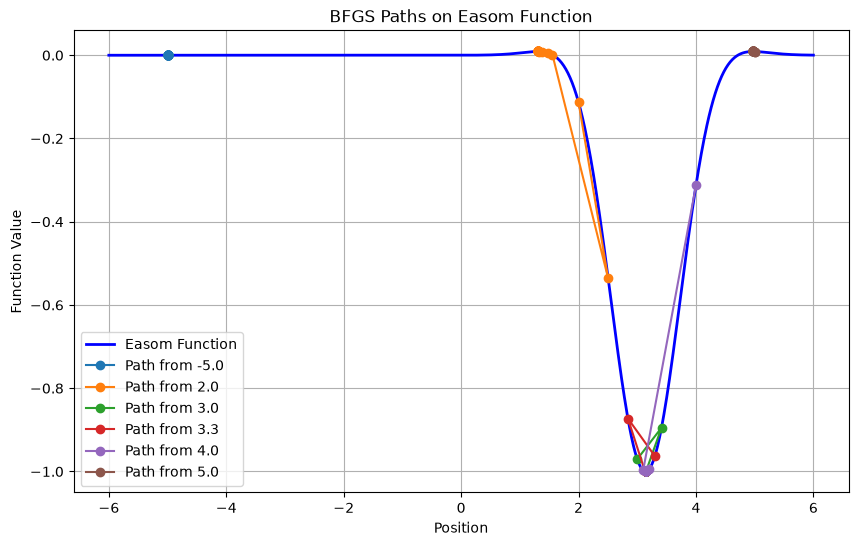

In [4]:
# ANA670 - Week 2 HW - Q3v1
import sympy as sp

x_sym = sp.Symbol('x')
f_sym = sp.cos(x_sym) * sp.exp(-(x_sym - sp.pi)**2)
df_sym = sp.diff(f_sym, x_sym)

f = sp.lambdify(x_sym, f_sym, 'numpy')
df = sp.lambdify(x_sym, df_sym, 'numpy')

def bfgs_minimize(initial_position):
    current_position = initial_position
    curvature_estimate = 1.0
    learning_rate = 1.00
    position_history = [current_position]
    
    for _ in range(50):
        current_gradient = df(current_position)
        step_direction = -curvature_estimate * current_gradient
        new_position = current_position + learning_rate * step_direction
        position_change = new_position - current_position
        gradient_change = df(new_position) - current_gradient
        if abs(gradient_change) > 1e-9: curvature_estimate = position_change / gradient_change
        current_position = new_position
        position_history.append(current_position)
    return current_position, position_history

starting_guesses = [-5.0, 2.0, 3.0, 3.3, 4.0, 5.0]

x_axis_range = np.linspace(-6, 6, 1000)
y_axis_heights = f(x_axis_range)

plt.figure(figsize=(10, 6))
plt.plot(x_axis_range, y_axis_heights, label="Easom Function", color="blue", linewidth=2)

print(f'v1 - Manual Optimization')
for guess in starting_guesses:
    final_pos, history = bfgs_minimize(guess)
    print(f"Result from {guess}: {final_pos}")
    plt.plot(history, f(np.array(history)), marker="o", label=f"Path from {guess}")

plt.title("BFGS Paths on Easom Function")
plt.xlabel("Position"); plt.ylabel("Function Value"); plt.legend(); plt.grid(True)
plt.show()

v2 - Scipy Optimization
Result from -5.0: -5.0
Result from 2.0: 3.1415925735622503
Result from 3.3: 3.1415926580982685
Result from 4.0: 3.1415927682004465
Result from 5.0: 6.820853998479656


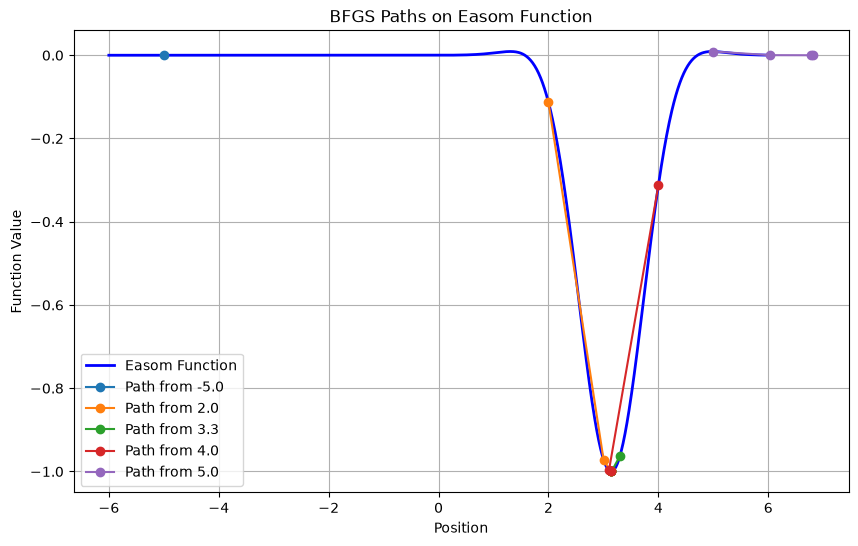

In [5]:
# ANA670 - Week 2 HW - Q3v2
from scipy.optimize import minimize

x_sym = sp.Symbol('x')
f_sym = sp.cos(x_sym) * sp.exp(-(x_sym - sp.pi)**2)
df_sym = sp.diff(f_sym, x_sym)

f = sp.lambdify(x_sym, f_sym, 'numpy')
df = sp.lambdify(x_sym, df_sym, 'numpy')

starting_guesses = [-5.0, 2.0, 3.3, 4.0, 5.0]

x_axis_range = np.linspace(-6, 6, 1000)
y_axis_heights = f(x_axis_range)

plt.figure(figsize=(10, 6))
plt.plot(x_axis_range, y_axis_heights, label="Easom Function", color="blue", linewidth=2)

print(f'v2 - Scipy Optimization')
for guess in starting_guesses:
    path = [guess]
    result = minimize(fun=f, x0=[guess], jac=df, method='BFGS', callback=lambda x: path.append(x[0]))
    print(f"Result from {guess}: {result.x[0]}")
    plt.plot(path, f(np.array(path)), marker="o", label=f"Path from {guess}")

plt.title("BFGS Paths on Easom Function")
plt.xlabel("Position"); plt.ylabel("Function Value"); plt.legend(); plt.grid(True)
plt.show()

$$f(x) = \left( \sum_{i=1}^n [x_i - \text{Target}_i]^{2p} \right)^{1/2p}$$

v1 - Manual Optimization
Start: [ 1.4 -1.4]
Target: [0.  1.5]
Solution  : [-0.   1.5]


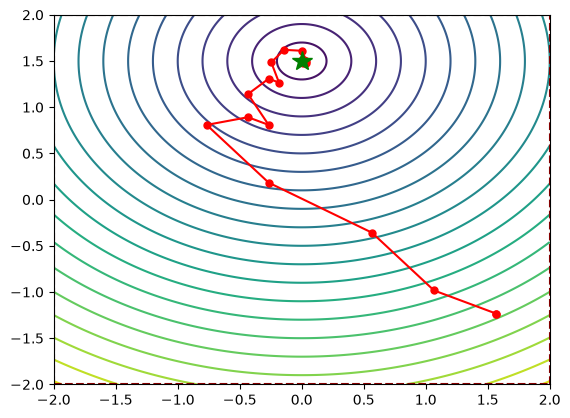

In [6]:
# ANA670 - Week 2 HW - Q4v1
def cost_function(position, p=1):
    position = np.asarray(position)
    n = len(position)
    if np.any(position <= -n) or np.any(position >= n):
        return 1e10
    target = np.array([(i + 1) - 1 / (i + 1) for i in range(n)])
    return np.sum((position - target) ** (2 * p)) ** (1 / (2 * p))

def nelder_mead(func, start, iters=100):
    simplex = [np.array(start, dtype=float)]
    for i in range(len(start)):
        vertex = np.array(start, dtype=float)
        vertex[i] += 0.5
        simplex.append(vertex)
    
    history = [np.mean(simplex, axis=0)]
    for _ in range(iters):
        simplex = sorted(simplex, key=func)
        history.append(np.mean(simplex, axis=0))
        best, worst = simplex[0], simplex[-1]
        center = np.mean(simplex[:-1], axis=0)
        reflect = center + 1.0 * (center - worst)
        if func(best) <= func(reflect) < func(simplex[-2]):
            simplex[-1] = reflect
            continue
        if func(reflect) < func(best):
            expand = center + 2.0 * (reflect - center)
            simplex[-1] = expand if func(expand) < func(reflect) else reflect
            continue
        contract = center + 0.5 * ((worst if func(reflect) >= func(worst) else reflect) - center)
        if func(contract) < min(func(reflect), func(worst)):
            simplex[-1] = contract
            continue
        for i in range(1, len(simplex)):
            simplex[i] = best + 0.5 * (simplex[i] - best)
    return simplex[0], np.array(history)

n = 2
start = [n - 0.6 if i % 2 == 0 else -n + 0.6 for i in range(n)]
best_fit, route = nelder_mead(cost_function, start=start)
target_coord = np.array([(i + 1) - 1 / (i + 1) for i in range(n)])

print(f'v1 - Manual Optimization')
print(f"Start: {np.round(start, 2)}")
print(f"Target: {np.round(target_coord, 2)}")
print(f"Solution  : {np.round(best_fit, 2)}")

if n <= 2:
    X, Y = np.meshgrid(np.linspace(-n, n, 200), np.linspace(-n, n, 1000))
    Z_clean = ((X - target_coord[0])**2 + (Y - target_coord[1])**2)**(0.5)
    plt.contour(X, Y, Z_clean, levels=25, cmap='viridis')
    plt.axhline(y=n, color='darkred', linestyle='--', linewidth=1.5)
    plt.axhline(y=-n, color='darkred', linestyle='--', linewidth=1.5)
    plt.axvline(x=n, color='darkred', linestyle='--', linewidth=1.5)
    plt.axvline(x=-n, color='darkred', linestyle='--', linewidth=1.5)
    plt.plot(route[:, 0], route[:, 1], 'ro-', markersize=5)
    plt.plot(best_fit[0], best_fit[1], 'g*', markersize=15)
    plt.xlim(-n, n); plt.ylim(-n, n)
    plt.show()

v2 - Scipy Optimization
Start: [ 1.4 -1.4]
Target: [0.  1.5]
Solution: [0.  1.5]


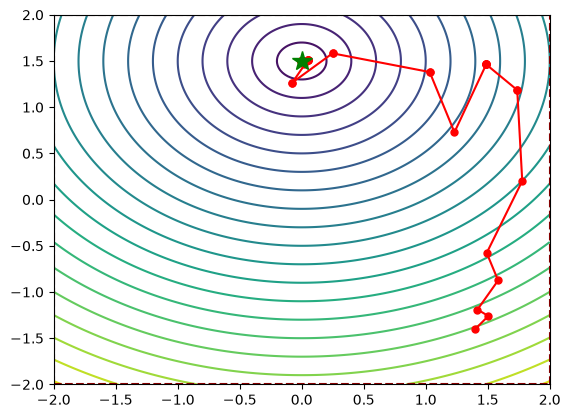

In [7]:
# ANA670 - Week 2 HW - Q4v2
def cost_function(position, p=1):
    position = np.asarray(position)
    n = len(position)
    if np.any(position <= -n) or np.any(position >= n):
        return 1e10
    target = np.array([(i + 1) - 1 / (i + 1) for i in range(n)])
    return np.sum((position - target) ** (2 * p)) ** (1 / (2 * p))

n = 2
start = [n - 0.6 if i % 2 == 0 else -n + 0.6 for i in range(n)]
history = []

def callback(xk):
    history.append(np.array(xk))

history.append(np.array(start))

scipy_res = minimize(cost_function, start, method='Nelder-Mead', callback=callback)
route = np.array(history)
best_fit = scipy_res.x
target_coord = np.array([(i + 1) - 1 / (i + 1) for i in range(n)])

print(f'v2 - Scipy Optimization')
print(f"Start: {np.round(start, 2)}")
print(f"Target: {np.round(target_coord, 2)}")
print(f"Solution: {np.round(best_fit, 2)}")

if n <= 2:
    X, Y = np.meshgrid(np.linspace(-n, n, 200), np.linspace(-n, n, 200))
    Z_clean = ((X - target_coord[0])**2 + (Y - target_coord[1])**2)**(0.5)
    plt.contour(X, Y, Z_clean, levels=25, cmap='viridis')
    plt.axhline(y=n, color='darkred', linestyle='--', linewidth=1.5)
    plt.axhline(y=-n, color='darkred', linestyle='--', linewidth=1.5)
    plt.axvline(x=n, color='darkred', linestyle='--', linewidth=1.5)
    plt.axvline(x=-n, color='darkred', linestyle='--', linewidth=1.5)
    plt.plot(route[:, 0], route[:, 1], 'ro-', markersize=5)
    plt.plot(best_fit[0], best_fit[1], 'g*', markersize=15)
    plt.xlim(-n, n); plt.ylim(-n, n)
    plt.show()


Method: Fixed Gradient Descent
Start: [2. 2.]
Target: [0. 0.]
Solution: [-0.02148  0.09101]
----------------------------------------
Method: Optimal Gradient Descent
Start: [2. 2.]
Target: [0. 0.]
Solution: [0. 0.]
----------------------------------------
Method: Newton Descent
Start: [2. 2.]
Target: [0. 0.]
Solution: [0. 0.]
----------------------------------------


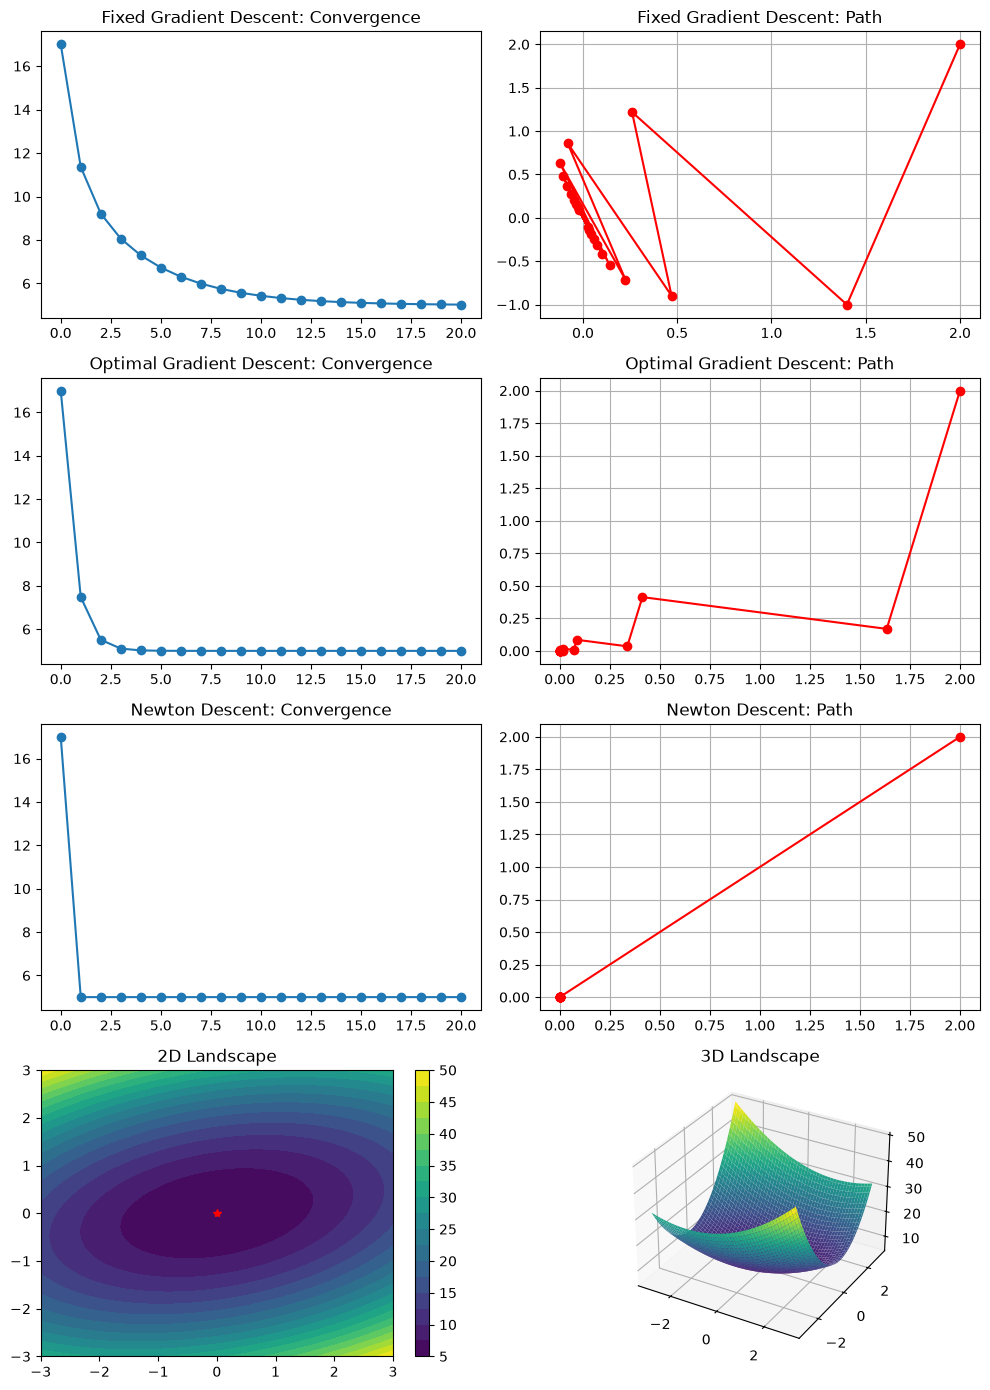

In [8]:
# ANA670 - Week 2 HW - Q5
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

x1_sym, x2_sym = sp.symbols('x1 x2')
f_expr = x1_sym**2 - x1_sym*x2_sym + 3*x2_sym**2 + 5
grad_expr = [sp.diff(f_expr, var) for var in (x1_sym, x2_sym)]
hessian_expr = [[sp.diff(f_expr, v1, v2) for v2 in (x1_sym, x2_sym)] for v1 in (x1_sym, x2_sym)]

f = sp.lambdify((x1_sym, x2_sym), f_expr, 'numpy')
gradient_func = sp.lambdify((x1_sym, x2_sym), grad_expr, 'numpy')
hessian_func = sp.lambdify((x1_sym, x2_sym), hessian_expr, 'numpy')

sol = sp.solve(grad_expr, (x1_sym, x2_sym))
target_min = np.array([float(sol[x1_sym]), float(sol[x2_sym])])
start_point, iterations = np.array([2.0, 2.0]), 20
fig, axs = plt.subplots(4, 2, figsize=(10, 14))
methods = ['Fixed Gradient Descent', 'Optimal Gradient Descent', 'Newton Descent']

for m_idx, name in enumerate(methods):
    x, path = start_point.copy(), [start_point]
    for _ in range(iterations):
        grad = np.array(gradient_func(x[0], x[1]))
        hessian = np.array(hessian_func(x[0], x[1]), dtype=float)
        if m_idx == 0: 
            alpha = 0.3
        elif m_idx == 1: 
            alpha = np.dot(grad, grad) / np.dot(grad, np.dot(hessian, grad))
        else: 
            alpha, grad = 1.0, np.linalg.solve(hessian, grad)
        x = x - alpha * grad
        path.append(x)
    path = np.array(path)
    print(f"Method: {name}\nStart: {start_point}\nTarget: {target_min}\nSolution: {np.round(x, 5)}\n" + "-"*40)
    
    axs[m_idx, 0].plot([f(p[0], p[1]) for p in path], 'o-')
    axs[m_idx, 0].set_title(f"{name}: Convergence")
    axs[m_idx, 1].plot(path[:, 0], path[:, 1], 'ro-')
    axs[m_idx, 1].set_title(f"{name}: Path")
    axs[m_idx, 1].grid(True)

X1, X2 = np.meshgrid(np.linspace(-3, 3, 100), np.linspace(-3, 3, 100))
Z = f(X1, X2)

contour = axs[3, 0].contourf(X1, X2, Z, levels=20, cmap='viridis')
fig.colorbar(contour, ax=axs[3, 0])
axs[3, 0].plot(0, 0, 'r*')
axs[3, 0].set_title("2D Landscape")

axs[3, 1].remove()
ax_3d = fig.add_subplot(4, 2, 8, projection='3d')
ax_3d.plot_surface(X1, X2, Z, cmap='viridis')
ax_3d.set_title("3D Landscape")

plt.tight_layout()
plt.show()

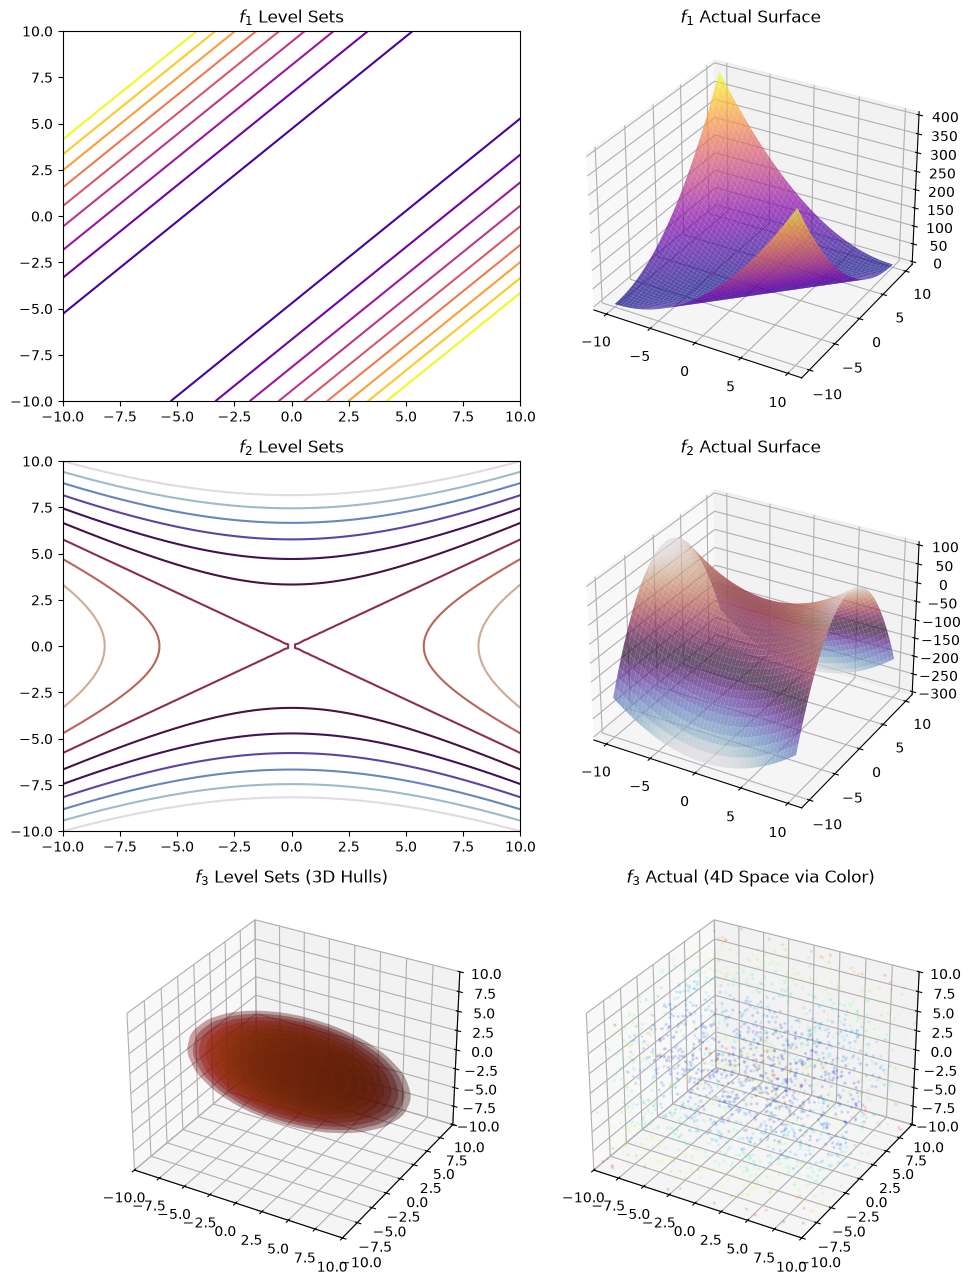

In [9]:
# ANA670 - Week 2 HW - Q6
valley_func = lambda x1, x2: (x1 - x2)**2
saddle_func = lambda x1, x2: x1**2 - 3 * (x2**2)
onion_func = lambda x1, x2, x3: x1**2 + 5 * (x2**2) + 3 * (x3**2)


grid_range = np.linspace(-10, 10, 100)
grid_x1, grid_x2 = np.meshgrid(grid_range, grid_range)
figure = plt.figure(figsize=(10, 13))
f1_levels = np.linspace(0, 200, 10)
f2_levels = np.linspace(-200, 100, 10)
f3_levels = np.linspace(10, 110, 10) 

# Valley
ax_f1_2d = figure.add_subplot(321)
ax_f1_2d.contour(grid_x1, grid_x2, valley_func(grid_x1, grid_x2), levels=f1_levels, cmap='plasma')
ax_f1_2d.set_title('$f_1$ Level Sets')

ax_f1_3d = figure.add_subplot(322, projection='3d')
ax_f1_3d.plot_surface(grid_x1, grid_x2, valley_func(grid_x1, grid_x2), cmap='plasma', alpha=0.7)
ax_f1_3d.set_title('$f_1$ Actual Surface')

# Saddle
ax_f2_2d = figure.add_subplot(323)
ax_f2_2d.contour(grid_x1, grid_x2, saddle_func(grid_x1, grid_x2), levels=f2_levels, cmap='twilight')
ax_f2_2d.set_title('$f_2$ Level Sets')

ax_f2_3d = figure.add_subplot(324, projection='3d')
ax_f2_3d.plot_surface(grid_x1, grid_x2, saddle_func(grid_x1, grid_x2), cmap='twilight', alpha=0.7)
ax_f2_3d.set_title('$f_2$ Actual Surface')

# Onion
ax_f3_3d_levels = figure.add_subplot(325, projection='3d')
for level_value in f3_levels:
    theta, phi = np.linspace(0, 2*np.pi, 30), np.linspace(0, np.pi, 30)
    ellipsoid_x = np.sqrt(level_value) * np.outer(np.cos(theta), np.sin(phi))
    ellipsoid_y = np.sqrt(level_value/5) * np.outer(np.sin(theta), np.sin(phi))
    ellipsoid_z = np.sqrt(level_value/3) * np.outer(np.ones(30), np.cos(phi))
    ax_f3_3d_levels.plot_surface(ellipsoid_x, ellipsoid_y, ellipsoid_z, color=plt.cm.jet(level_value/100), alpha=0.2, edgecolor='none')
ax_f3_3d_levels.set_title('$f_3$ Level Sets (3D Hulls)')
ax_f3_3d_levels.set_xlim(-10, 10); ax_f3_3d_levels.set_ylim(-10, 10); ax_f3_3d_levels.set_zlim(-10, 10)

ax_f3_4d_scatter = figure.add_subplot(326, projection='3d')
random_points = np.random.uniform(-10, 10, (2000, 3))
output_values = onion_func(random_points[:, 0], random_points[:, 1], random_points[:, 2])
ax_f3_4d_scatter.scatter(random_points[:, 0], random_points[:, 1], random_points[:, 2], c=output_values, cmap='jet', s=2, alpha=0.4)
ax_f3_4d_scatter.set_title('$f_3$ Actual (4D Space via Color)')
ax_f3_4d_scatter.set_xlim(-10, 10); ax_f3_4d_scatter.set_ylim(-10, 10); ax_f3_4d_scatter.set_zlim(-10, 10)

plt.tight_layout()
plt.show()

In [10]:
import matplotlib.colors as mcolors

onion_func = lambda x1, x2, x3: x1**2 + 5 * (x2**2) + 3 * (x3**2)
np.random.seed(42)

random_points = np.random.randint(low=-10, high=11, size=(2000, 3))
output_values = onion_func(random_points[:, 0], random_points[:, 1], random_points[:, 2])

sort_indices = np.argsort(output_values)
output_values = output_values[sort_indices]
random_points = random_points[sort_indices]
random_sample_indices = np.random.choice(2000, size=10, replace=False)
random_sample_indices.sort()

css4_colors = mcolors.CSS4_COLORS
color_names = list(css4_colors.keys())
rgb_lookup_table = np.array([mcolors.to_rgb(css4_colors[name]) for name in color_names])
norm = plt.Normalize(vmin=0, vmax=900)
color_mapper = plt.cm.jet

print(f"{'Pt#':<8}{'x1':<8}{'x2':<8}{'x3':<8}{'f(x1,x2,x3)':<18}{'Closest Official Color Name':<25}")
print("-" * 75)

for array_position, i in enumerate(random_sample_indices):
    val = int(output_values[i])
    target_rgb = np.array(color_mapper(norm(val))[:3])
    distances = np.linalg.norm(rgb_lookup_table - target_rgb, axis=1)
    closest_index = np.argmin(distances)
    exact_color_name = color_names[closest_index]
    print(f"{array_position+1:<8}{int(random_points[i,0]):<8d}{int(random_points[i,1]):<8d}{int(random_points[i,2]):<8d}{val:<18d}{exact_color_name:<25}")

Pt#     x1      x2      x3      f(x1,x2,x3)       Closest Official Color Name
---------------------------------------------------------------------------
1       0       1       -5      80                mediumblue               
2       5       3       -4      118               blue                     
3       10      -2      -5      195               dodgerblue               
4       2       3       -8      241               dodgerblue               
5       3       0       -9      252               dodgerblue               
6       -10     -5      4       273               deepskyblue              
7       -1      7       4       294               deepskyblue              
8       3       -5      -9      377               turquoise                
9       -9      -8      6       509               greenyellow              
10      -10     -9      -10     805               red                      


Eq:
  2       2       2
x₁  + 2⋅x₂  + 3⋅x₃ 

Hessian Matrix:
⎡ ∂²f/(∂x1²)=2   ∂²f/(∂x1∂x2)=0  ∂²f/(∂x1∂x3)=0⎤
⎢                                              ⎥
⎢∂²f/(∂x2∂x1)=0   ∂²f/(∂x2²)=4   ∂²f/(∂x2∂x3)=0⎥
⎢                                              ⎥
⎣∂²f/(∂x3∂x1)=0  ∂²f/(∂x3∂x2)=0   ∂²f/(∂x3²)=6 ⎦

Evals: [2, 4, 6] | Convex if matix is positive semi-definite (PSD): True


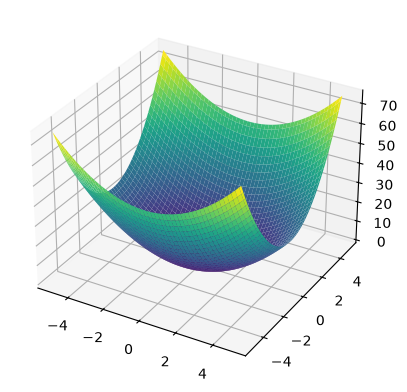

In [11]:
dims = 3
vars = sp.symbols(f'x1:{dims+1}')
func = sum(idx * vars[idx-1]**2 for idx in range(1, dims + 1))
print("Eq:")
sp.pprint(func)

custom_grid = []
for vj in vars:
    row = []
    for vk in vars:
        ans = sp.diff(func, vj, vk)
        j, k = vj.name[1:], vk.name[1:]
        notation = f"∂²f/(∂x{j}²)" if j == k else f"∂²f/(∂x{j}∂x{k})"
        row.append(sp.Symbol(f"{notation}={ans}"))
    custom_grid.append(row)
print("\nHessian Matrix:")
sp.pprint(sp.Matrix(custom_grid))

hess = sp.Matrix([[sp.diff(func, vj, vk) for vk in vars] for vj in vars])
evals = list(hess.eigenvals().keys())
print("\nEvals:", evals, "| Convex if matix is positive semi-definite (PSD):", all(v >= 0 for v in evals))

x1, x2 = np.meshgrid(np.linspace(-5, 5, 100), np.linspace(-5, 5, 100))
z_val = 1 * x1**2 + 2 * x2**2
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x1, x2, z_val, cmap='viridis')
plt.show()